# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


False

# Importamos los datos

In [4]:
path = '../../../data/noisy/Campo 20 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')

In [6]:
np.shape(campvectrain)

(7000, 2, 20, 20)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')

In [10]:
np.shape(campvectest)

(2000, 2, 20, 20)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(2000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')

In [14]:
np.shape(campvecval)

(1000, 2, 20, 20)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(1000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(2, 20, 20), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [43]:
import optuna
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l1, l2
import optuna

def objective(trial):
    model = Sequential()
    
    model.add(Flatten(input_shape=(2, 20, 20)))  # Tus dimensiones de entrada
    n_dense_layers = trial.suggest_int("n_dense_layers", 1, 8)
    
    for i in range(n_dense_layers):
        num_units = trial.suggest_int(f"num_units_{i+1}", 16, 128)
        activation = trial.suggest_categorical(f"dense_activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"dense_kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"dense_kernel_regularizer_{i+1}", ['l1', 'l2'])

        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)

        model.add(Dense(num_units, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
    
        # Decide si agregar una capa de Dropout después de esta capa densa
        add_dropout = trial.suggest_categorical(f"add_dropout_after_dense_{i+1}", [True, False])
        if add_dropout:
            dropout_rate = trial.suggest_float(f"dropout_rate_after_dense_{i+1}", 0.1, 0.5)
            model.add(Dropout(dropout_rate))
            
    model.add(Dense(7, activation=custom_activation))  # Asumiendo que tienes una función 'custom_activation'
    
    optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
  
    model.compile(optimizer=optimizer, loss= 'mean_squared_error', metrics=metrics)
    
    history = model.fit(
        train_dataset, 
        validation_data=val_dataset, 
        epochs=20,  
        callbacks=[ early_stop]
    )
    
    val_mean_metric = history.history['val_mean_metric'][-1]
    
    return val_mean_metric

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=300)

print(f'Número de trials finalizados: {len(study.trials)}')
print(f'Mejor trial:')
trial = study.best_trial

print(f'  Valor: {trial.value}')
print('  Parámetros: ')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

[I 2023-10-26 11:58:16,803] A new study created in memory with name: no-name-934e4655-82fe-4618-af90-6be57dfa8d65


Epoch 1/20
70/70 [==============================] - 1s 5ms/step - loss: 10.3019 - a_1: 2.4919 - a_2: 2.5435 - b_1: 2.7111 - b_2: 2.7749 - d_1: 2.3075 - d_2: 2.7314 - n: 1.2494 - mean_metric: 0.5233 - val_loss: 8.3624 - val_a_1: 2.4019 - val_a_2: 2.4787 - val_b_1: 2.5358 - val_b_2: 2.7204 - val_d_1: 1.3921 - val_d_2: 2.4676 - val_n: 1.2262 - val_mean_metric: 0.4679
Epoch 2/20
70/70 [==============================] - 0s 2ms/step - loss: 7.6776 - a_1: 2.4666 - a_2: 2.4992 - b_1: 2.5446 - b_2: 2.6221 - d_1: 1.5359 - d_2: 1.7514 - n: 1.2181 - mean_metric: 0.4556 - val_loss: 6.9252 - val_a_1: 2.3973 - val_a_2: 2.4424 - val_b_1: 2.4406 - val_b_2: 2.6118 - val_d_1: 1.3265 - val_d_2: 1.3138 - val_n: 1.2325 - val_mean_metric: 0.4230
Epoch 3/20
70/70 [==============================] - 0s 2ms/step - loss: 7.0679 - a_1: 2.4588 - a_2: 2.4825 - b_1: 2.4899 - b_2: 2.5496 - d_1: 1.4808 - d_2: 1.4933 - n: 1.2135 - mean_metric: 0.4410 - val_loss: 6.6770 - val_a_1: 2.3945 - val_a_2: 2.4301 - val_b_1: 2.41

[I 2023-10-26 11:58:21,017] Trial 0 finished with value: 0.3272130489349365 and parameters: {'n_dense_layers': 7, 'num_units_1': 53, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'random_normal', 'dense_kernel_regularizer_1': 'l1', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.4814662360683907, 'num_units_2': 32, 'dense_activation_2': 'sigmoid', 'dense_kernel_initializer_2': 'glorot_uniform', 'dense_kernel_regularizer_2': 'l1', 'add_dropout_after_dense_2': True, 'dropout_rate_after_dense_2': 0.36080134355401816, 'num_units_3': 125, 'dense_activation_3': 'tanh', 'dense_kernel_initializer_3': 'HeNormal', 'dense_kernel_regularizer_3': 'l2', 'add_dropout_after_dense_3': False, 'num_units_4': 102, 'dense_activation_4': 'tanh', 'dense_kernel_initializer_4': 'random_normal', 'dense_kernel_regularizer_4': 'l1', 'add_dropout_after_dense_4': False, 'num_units_5': 36, 'dense_activation_5': 'relu', 'dense_kernel_initializer_5': 'random_normal', 'dense_kernel_regu

Epoch 1/20
70/70 [==============================] - 1s 5ms/step - loss: 9.7875 - a_1: 2.5926 - a_2: 2.5864 - b_1: 2.7380 - b_2: 2.6986 - d_1: 2.2278 - d_2: 2.1316 - n: 1.4653 - mean_metric: 0.5117 - val_loss: 7.7503 - val_a_1: 2.4272 - val_a_2: 2.4495 - val_b_1: 2.4932 - val_b_2: 2.5116 - val_d_1: 1.5076 - val_d_2: 1.5797 - val_n: 1.3045 - val_mean_metric: 0.4387
Epoch 2/20
70/70 [==============================] - 0s 3ms/step - loss: 8.2802 - a_1: 2.5217 - a_2: 2.5540 - b_1: 2.4794 - b_2: 2.4649 - d_1: 1.6857 - d_2: 1.6799 - n: 1.3641 - mean_metric: 0.4591 - val_loss: 6.9633 - val_a_1: 2.4081 - val_a_2: 2.4513 - val_b_1: 2.1521 - val_b_2: 2.2558 - val_d_1: 1.3360 - val_d_2: 1.3959 - val_n: 1.2923 - val_mean_metric: 0.4085
Epoch 3/20
70/70 [==============================] - 0s 3ms/step - loss: 7.4649 - a_1: 2.5051 - a_2: 2.5276 - b_1: 2.0704 - b_2: 2.1367 - d_1: 1.6428 - d_2: 1.5919 - n: 1.3363 - mean_metric: 0.4299 - val_loss: 5.9558 - val_a_1: 2.3971 - val_a_2: 2.4295 - val_b_1: 1.676

[I 2023-10-26 11:58:25,373] Trial 1 finished with value: 0.28928834199905396 and parameters: {'n_dense_layers': 4, 'num_units_1': 43, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'glorot_uniform', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.2358698952491594, 'num_units_2': 58, 'dense_activation_2': 'sigmoid', 'dense_kernel_initializer_2': 'glorot_uniform', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': True, 'dropout_rate_after_dense_2': 0.49017527137919603, 'num_units_3': 121, 'dense_activation_3': 'tanh', 'dense_kernel_initializer_3': 'glorot_uniform', 'dense_kernel_regularizer_3': 'l2', 'add_dropout_after_dense_3': True, 'dropout_rate_after_dense_3': 0.10082878260072095, 'num_units_4': 125, 'dense_activation_4': 'relu', 'dense_kernel_initializer_4': 'HeNormal', 'dense_kernel_regularizer_4': 'l1', 'add_dropout_after_dense_4': True, 'dropout_rate_after_dense_4': 0.46167833302183237}. Best is tr

Epoch 1/20
70/70 [==============================] - 1s 5ms/step - loss: 12.6471 - a_1: 2.5264 - a_2: 2.5657 - b_1: 2.7859 - b_2: 2.7852 - d_1: 2.6526 - d_2: 2.4129 - n: 1.3090 - mean_metric: 0.5303 - val_loss: 9.7007 - val_a_1: 2.4053 - val_a_2: 2.4654 - val_b_1: 2.7467 - val_b_2: 2.6453 - val_d_1: 2.2802 - val_d_2: 1.7337 - val_n: 1.2338 - val_mean_metric: 0.4768
Epoch 2/20
70/70 [==============================] - 0s 3ms/step - loss: 9.1264 - a_1: 2.4966 - a_2: 2.5233 - b_1: 2.6995 - b_2: 2.6344 - d_1: 2.1039 - d_2: 1.6772 - n: 1.2598 - mean_metric: 0.4792 - val_loss: 7.7191 - val_a_1: 2.3965 - val_a_2: 2.4244 - val_b_1: 2.4947 - val_b_2: 2.6096 - val_d_1: 1.3575 - val_d_2: 1.3232 - val_n: 1.2240 - val_mean_metric: 0.4250
Epoch 3/20
70/70 [==============================] - 0s 3ms/step - loss: 7.8841 - a_1: 2.4648 - a_2: 2.4755 - b_1: 2.5274 - b_2: 2.5434 - d_1: 1.5606 - d_2: 1.5136 - n: 1.2657 - mean_metric: 0.4467 - val_loss: 7.2191 - val_a_1: 2.3747 - val_a_2: 2.4006 - val_b_1: 2.37

... (592 outputs left out)

[I 2023-10-26 12:18:55,637] Trial 298 finished with value: 0.17022953927516937 and parameters: {'n_dense_layers': 2, 'num_units_1': 124, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'random_normal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.2395278350896241, 'num_units_2': 109, 'dense_activation_2': 'relu', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': False}. Best is trial 266 with value: 0.15327300131320953.


Epoch 1/20
70/70 [==============================] - 1s 8ms/step - loss: 4.4610 - a_1: 2.0806 - a_2: 2.1681 - b_1: 1.5602 - b_2: 1.6298 - d_1: 1.1538 - d_2: 1.1237 - n: 1.2763 - mean_metric: 0.3423 - val_loss: 3.0774 - val_a_1: 1.6218 - val_a_2: 1.7620 - val_b_1: 1.2377 - val_b_2: 1.1912 - val_d_1: 0.9160 - val_d_2: 0.9081 - val_n: 1.2376 - val_mean_metric: 0.2728
Epoch 2/20
70/70 [==============================] - 0s 4ms/step - loss: 2.6749 - a_1: 1.4707 - a_2: 1.5033 - b_1: 1.1095 - b_2: 1.1300 - d_1: 0.8549 - d_2: 0.8783 - n: 1.1646 - mean_metric: 0.2525 - val_loss: 2.3400 - val_a_1: 1.2574 - val_a_2: 1.2542 - val_b_1: 1.0606 - val_b_2: 1.0540 - val_d_1: 0.8180 - val_d_2: 0.8652 - val_n: 1.1269 - val_mean_metric: 0.2287
Epoch 3/20
70/70 [==============================] - 0s 4ms/step - loss: 2.2244 - a_1: 1.2310 - a_2: 1.2393 - b_1: 0.9989 - b_2: 0.9938 - d_1: 0.8070 - d_2: 0.8258 - n: 1.0934 - mean_metric: 0.2239 - val_loss: 2.0781 - val_a_1: 1.2126 - val_a_2: 1.1531 - val_b_1: 0.923

[I 2023-10-26 12:19:01,499] Trial 299 finished with value: 0.16595040261745453 and parameters: {'n_dense_layers': 2, 'num_units_1': 126, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'random_normal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': False, 'num_units_2': 113, 'dense_activation_2': 'relu', 'dense_kernel_initializer_2': 'HeNormal', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': False}. Best is trial 266 with value: 0.15327300131320953.


Número de trials finalizados: 300
Mejor trial:
  Valor: 0.15327300131320953
  Parámetros: 
    n_dense_layers: 2
    num_units_1: 124
    dense_activation_1: tanh
    dense_kernel_initializer_1: random_normal
    dense_kernel_regularizer_1: l2
    add_dropout_after_dense_1: False
    num_units_2: 106
    dense_activation_2: relu
    dense_kernel_initializer_2: random_normal
    dense_kernel_regularizer_2: l2
    add_dropout_after_dense_2: False


In [20]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [34]:
model = Sequential()
model.add(Flatten(input_shape=(2, 20, 20)))
model.add(BatchNormalization())
model.add(Dense(100, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dense(100, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(100, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dense(50, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(BatchNormalization())
model.add(Dense(50, activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.2))
model.add(Dense(50, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dense(7, activation = custom_activation
               ))

In [63]:
from keras.models import Sequential
from keras.layers import Flatten, Dense, Dropout
from keras.optimizers import Adam
from keras.regularizers import l1, l2

# Inicializa el modelo
model = Sequential()

# Añade la capa Flatten con las dimensiones de entrada (esto es solo un ejemplo, necesitarás especificar las dimensiones correctas)
model.add(Flatten(input_shape=(2, 20, 20)))  # Tus dimensiones de entrada

# Primer bloque denso
model.add(Dense(71, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))

# Segundo bloque denso con Dropout
model.add(Dense(77, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(Dropout(0.1127))

model.add(Dense(7, activation=custom_activation))
model.summary()

Model: "sequential_305"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_305 (Flatten)       (None, 800)               0         
                                                                 
 dense_1107 (Dense)          (None, 71)                56871     
                                                                 
 dense_1108 (Dense)          (None, 77)                5544      
                                                                 
 dropout_101 (Dropout)       (None, 77)                0         
                                                                 
 dense_1109 (Dense)          (None, 7)                 546       
                                                                 
Total params: 62,961
Trainable params: 62,961
Non-trainable params: 0
_________________________________________________________________


In [73]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.regularizers import l2

# Inicializar el modelo
model = Sequential()

# Aplanar para capas densas si es necesario (por ejemplo, si estás usando imágenes)
model.add(Flatten(input_shape=(2, 20, 20)))  # Tus dimensiones de entrada

# Capas densas
model.add(Dense(124, activation='tanh', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(Dense(106, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))

model.add(Dense(7, activation=custom_activation))

# Resumen del modelo
model.summary()


Model: "sequential_306"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_306 (Flatten)       (None, 800)               0         
                                                                 
 dense_1110 (Dense)          (None, 124)               99324     
                                                                 
 dense_1111 (Dense)          (None, 106)               13250     
                                                                 
 dense_1112 (Dense)          (None, 7)                 749       
                                                                 
Total params: 113,323
Trainable params: 113,323
Non-trainable params: 0
_________________________________________________________________


In [74]:
model.summary()

Model: "sequential_306"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_306 (Flatten)       (None, 800)               0         
                                                                 
 dense_1110 (Dense)          (None, 124)               99324     
                                                                 
 dense_1111 (Dense)          (None, 106)               13250     
                                                                 
 dense_1112 (Dense)          (None, 7)                 749       
                                                                 
Total params: 113,323
Trainable params: 113,323
Non-trainable params: 0
_________________________________________________________________


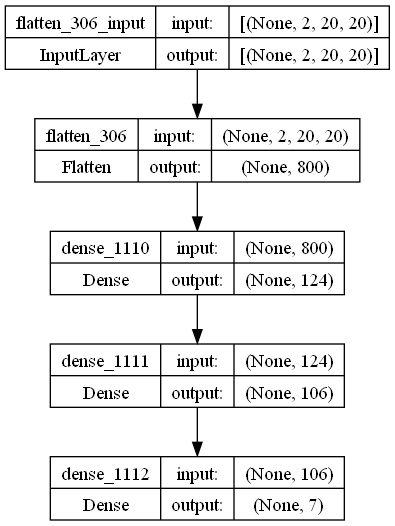

In [75]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [76]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [77]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [78]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [79]:
model.compile(optimizer=optimizer,
              loss= 'mean_squared_error',
              metrics=metrics)

In [80]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [81]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 1s 5ms/step - loss: 4.4825 - a_1: 2.2760 - a_2: 2.2852 - b_1: 1.6281 - b_2: 1.6724 - d_1: 1.1203 - d_2: 1.1366 - n: 1.2906 - mean_metric: 0.3553 - val_loss: 3.0990 - val_a_1: 1.8343 - val_a_2: 1.9526 - val_b_1: 1.1892 - val_b_2: 1.1776 - val_d_1: 0.9427 - val_d_2: 0.8921 - val_n: 1.2108 - val_mean_metric: 0.2828 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 0s 3ms/step - loss: 2.5581 - a_1: 1.5949 - a_2: 1.5619 - b_1: 1.1152 - b_2: 1.1030 - d_1: 0.8534 - d_2: 0.8702 - n: 1.1757 - mean_metric: 0.2577 - val_loss: 2.1316 - val_a_1: 1.3212 - val_a_2: 1.2918 - val_b_1: 1.0141 - val_b_2: 1.0053 - val_d_1: 0.7965 - val_d_2: 0.7937 - val_n: 1.1660 - val_mean_metric: 0.2272 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 0s 4ms/step - loss: 2.0678 - a_1: 1.2749 - a_2: 1.2498 - b_1: 0.9919 - b_2: 0.9947 - d_1: 0.8075 - d_2: 0.8069 - n: 1.1543 - mean_metric: 0.2266 - val_loss: 1.9299 - val_a_1: 1.1898 - 

70/70 [==============================] - 0s 3ms/step - loss: 1.2120 - a_1: 0.8456 - a_2: 0.8284 - b_1: 0.7643 - b_2: 0.7567 - d_1: 0.6668 - d_2: 0.6803 - n: 0.6401 - mean_metric: 0.1613 - val_loss: 1.2286 - val_a_1: 0.9620 - val_a_2: 0.7979 - val_b_1: 0.7673 - val_b_2: 0.7683 - val_d_1: 0.6458 - val_d_2: 0.6638 - val_n: 0.6011 - val_mean_metric: 0.1601 - lr: 0.0010
Epoch 23/1000
70/70 [==============================] - 0s 3ms/step - loss: 1.1915 - a_1: 0.8428 - a_2: 0.8146 - b_1: 0.7523 - b_2: 0.7378 - d_1: 0.6663 - d_2: 0.6676 - n: 0.6343 - mean_metric: 0.1593 - val_loss: 1.1905 - val_a_1: 0.8141 - val_a_2: 0.8103 - val_b_1: 0.7396 - val_b_2: 0.7417 - val_d_1: 0.6609 - val_d_2: 0.6603 - val_n: 0.6639 - val_mean_metric: 0.1566 - lr: 0.0010
Epoch 24/1000
70/70 [==============================] - 0s 3ms/step - loss: 1.1727 - a_1: 0.8285 - a_2: 0.8126 - b_1: 0.7460 - b_2: 0.7321 - d_1: 0.6613 - d_2: 0.6591 - n: 0.6201 - mean_metric: 0.1575 - val_loss: 1.2471 - val_a_1: 1.0100 - val_a_2: 0.

70/70 [==============================] - 0s 3ms/step - loss: 1.0590 - a_1: 0.7869 - a_2: 0.7689 - b_1: 0.7099 - b_2: 0.6961 - d_1: 0.6290 - d_2: 0.6415 - n: 0.5429 - mean_metric: 0.1487 - val_loss: 1.1661 - val_a_1: 0.9235 - val_a_2: 0.7844 - val_b_1: 0.7509 - val_b_2: 0.7140 - val_d_1: 0.6462 - val_d_2: 0.6495 - val_n: 0.6162 - val_mean_metric: 0.1564 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 0s 3ms/step - loss: 1.0716 - a_1: 0.7927 - a_2: 0.7689 - b_1: 0.7170 - b_2: 0.7085 - d_1: 0.6298 - d_2: 0.6446 - n: 0.5627 - mean_metric: 0.1502 - val_loss: 1.1202 - val_a_1: 0.8669 - val_a_2: 0.7801 - val_b_1: 0.7219 - val_b_2: 0.7475 - val_d_1: 0.6161 - val_d_2: 0.6352 - val_n: 0.5885 - val_mean_metric: 0.1525 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 0s 3ms/step - loss: 1.0490 - a_1: 0.7855 - a_2: 0.7568 - b_1: 0.6994 - b_2: 0.6936 - d_1: 0.6249 - d_2: 0.6364 - n: 0.5523 - mean_metric: 0.1478 - val_loss: 1.2069 - val_a_1: 1.0438 - val_a_2: 0.

70/70 [==============================] - 0s 3ms/step - loss: 1.0340 - a_1: 0.7912 - a_2: 0.7727 - b_1: 0.6959 - b_2: 0.6913 - d_1: 0.6193 - d_2: 0.6288 - n: 0.5511 - mean_metric: 0.1479 - val_loss: 1.0972 - val_a_1: 0.8630 - val_a_2: 0.7959 - val_b_1: 0.7142 - val_b_2: 0.7312 - val_d_1: 0.6058 - val_d_2: 0.6283 - val_n: 0.5681 - val_mean_metric: 0.1509 - lr: 0.0010
Epoch 65/1000
70/70 [==============================] - 0s 3ms/step - loss: 1.0026 - a_1: 0.7630 - a_2: 0.7497 - b_1: 0.6833 - b_2: 0.6834 - d_1: 0.6119 - d_2: 0.6261 - n: 0.5313 - mean_metric: 0.1448 - val_loss: 1.1819 - val_a_1: 1.0045 - val_a_2: 0.8001 - val_b_1: 0.8083 - val_b_2: 0.7515 - val_d_1: 0.6366 - val_d_2: 0.6608 - val_n: 0.5311 - val_mean_metric: 0.1597 - lr: 0.0010
Epoch 66/1000
70/70 [==============================] - 0s 3ms/step - loss: 1.0208 - a_1: 0.7727 - a_2: 0.7671 - b_1: 0.6963 - b_2: 0.6986 - d_1: 0.6206 - d_2: 0.6263 - n: 0.5356 - mean_metric: 0.1468 - val_loss: 1.0868 - val_a_1: 0.8384 - val_a_2: 0.

70/70 [==============================] - 0s 3ms/step - loss: 0.9735 - a_1: 0.7543 - a_2: 0.7437 - b_1: 0.6727 - b_2: 0.6747 - d_1: 0.6067 - d_2: 0.6157 - n: 0.5180 - mean_metric: 0.1428 - val_loss: 1.0545 - val_a_1: 0.7913 - val_a_2: 0.7840 - val_b_1: 0.7006 - val_b_2: 0.7131 - val_d_1: 0.6103 - val_d_2: 0.6330 - val_n: 0.5603 - val_mean_metric: 0.1474 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9700 - a_1: 0.7533 - a_2: 0.7483 - b_1: 0.6688 - b_2: 0.6732 - d_1: 0.6071 - d_2: 0.6068 - n: 0.5080 - mean_metric: 0.1421 - val_loss: 1.0915 - val_a_1: 0.8796 - val_a_2: 0.7813 - val_b_1: 0.7308 - val_b_2: 0.7183 - val_d_1: 0.6107 - val_d_2: 0.6442 - val_n: 0.5432 - val_mean_metric: 0.1510 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9753 - a_1: 0.7621 - a_2: 0.7463 - b_1: 0.6689 - b_2: 0.6766 - d_1: 0.6011 - d_2: 0.6149 - n: 0.5197 - mean_metric: 0.1429 - val_loss: 1.0695 - val_a_1: 0.8589 - val_a_2: 0.

70/70 [==============================] - 0s 3ms/step - loss: 0.9589 - a_1: 0.7626 - a_2: 0.7504 - b_1: 0.6632 - b_2: 0.6678 - d_1: 0.5997 - d_2: 0.6047 - n: 0.5094 - mean_metric: 0.1419 - val_loss: 1.1302 - val_a_1: 0.8981 - val_a_2: 0.8123 - val_b_1: 0.7727 - val_b_2: 0.7218 - val_d_1: 0.6125 - val_d_2: 0.6370 - val_n: 0.6055 - val_mean_metric: 0.1556 - lr: 9.9450e-04
Epoch 107/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9546 - a_1: 0.7540 - a_2: 0.7399 - b_1: 0.6618 - b_2: 0.6682 - d_1: 0.6051 - d_2: 0.6029 - n: 0.5133 - mean_metric: 0.1415 - val_loss: 1.0816 - val_a_1: 0.8750 - val_a_2: 0.7826 - val_b_1: 0.7579 - val_b_2: 0.7144 - val_d_1: 0.6456 - val_d_2: 0.6354 - val_n: 0.5312 - val_mean_metric: 0.1520 - lr: 9.9340e-04
Epoch 108/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9519 - a_1: 0.7547 - a_2: 0.7465 - b_1: 0.6661 - b_2: 0.6602 - d_1: 0.6004 - d_2: 0.5946 - n: 0.5161 - mean_metric: 0.1413 - val_loss: 1.0929 - val_a_1: 0.9002 - v

70/70 [==============================] - 0s 3ms/step - loss: 0.9499 - a_1: 0.7530 - a_2: 0.7482 - b_1: 0.6522 - b_2: 0.6775 - d_1: 0.5945 - d_2: 0.5985 - n: 0.5104 - mean_metric: 0.1412 - val_loss: 1.0958 - val_a_1: 0.8896 - val_a_2: 0.7840 - val_b_1: 0.7009 - val_b_2: 0.7021 - val_d_1: 0.6694 - val_d_2: 0.6339 - val_n: 0.5757 - val_mean_metric: 0.1524 - lr: 9.7140e-04
Epoch 128/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9435 - a_1: 0.7525 - a_2: 0.7271 - b_1: 0.6584 - b_2: 0.6651 - d_1: 0.6045 - d_2: 0.5913 - n: 0.5160 - mean_metric: 0.1406 - val_loss: 1.0755 - val_a_1: 0.8316 - val_a_2: 0.7989 - val_b_1: 0.6923 - val_b_2: 0.7115 - val_d_1: 0.6283 - val_d_2: 0.6358 - val_n: 0.5847 - val_mean_metric: 0.1502 - lr: 9.7030e-04
Epoch 129/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9575 - a_1: 0.7753 - a_2: 0.7408 - b_1: 0.6612 - b_2: 0.6692 - d_1: 0.5965 - d_2: 0.5968 - n: 0.5266 - mean_metric: 0.1422 - val_loss: 1.1334 - val_a_1: 0.8412 - v

70/70 [==============================] - 0s 3ms/step - loss: 0.9222 - a_1: 0.7379 - a_2: 0.7207 - b_1: 0.6523 - b_2: 0.6547 - d_1: 0.5867 - d_2: 0.5872 - n: 0.5088 - mean_metric: 0.1385 - val_loss: 1.1013 - val_a_1: 0.8603 - val_a_2: 0.8205 - val_b_1: 0.7036 - val_b_2: 0.7185 - val_d_1: 0.6420 - val_d_2: 0.6287 - val_n: 0.6020 - val_mean_metric: 0.1531 - lr: 9.4830e-04
Epoch 149/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9115 - a_1: 0.7298 - a_2: 0.7159 - b_1: 0.6466 - b_2: 0.6499 - d_1: 0.5911 - d_2: 0.5827 - n: 0.4945 - mean_metric: 0.1373 - val_loss: 1.0882 - val_a_1: 0.8824 - val_a_2: 0.8080 - val_b_1: 0.6981 - val_b_2: 0.7171 - val_d_1: 0.6348 - val_d_2: 0.6447 - val_n: 0.5325 - val_mean_metric: 0.1513 - lr: 9.4720e-04
Epoch 150/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9267 - a_1: 0.7357 - a_2: 0.7239 - b_1: 0.6650 - b_2: 0.6571 - d_1: 0.5937 - d_2: 0.5937 - n: 0.5035 - mean_metric: 0.1392 - val_loss: 1.1349 - val_a_1: 0.9228 - v

70/70 [==============================] - 0s 3ms/step - loss: 0.9222 - a_1: 0.7473 - a_2: 0.7351 - b_1: 0.6485 - b_2: 0.6395 - d_1: 0.5951 - d_2: 0.5769 - n: 0.5090 - mean_metric: 0.1386 - val_loss: 1.0733 - val_a_1: 0.8413 - val_a_2: 0.7984 - val_b_1: 0.7097 - val_b_2: 0.6970 - val_d_1: 0.6402 - val_d_2: 0.6278 - val_n: 0.5376 - val_mean_metric: 0.1493 - lr: 9.2520e-04
Epoch 170/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9173 - a_1: 0.7394 - a_2: 0.7154 - b_1: 0.6548 - b_2: 0.6386 - d_1: 0.5972 - d_2: 0.5845 - n: 0.5159 - mean_metric: 0.1384 - val_loss: 1.0609 - val_a_1: 0.8078 - val_a_2: 0.7819 - val_b_1: 0.7130 - val_b_2: 0.6972 - val_d_1: 0.6343 - val_d_2: 0.6311 - val_n: 0.5568 - val_mean_metric: 0.1483 - lr: 9.2410e-04
Epoch 171/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.9059 - a_1: 0.7393 - a_2: 0.7176 - b_1: 0.6412 - b_2: 0.6386 - d_1: 0.5833 - d_2: 0.5764 - n: 0.5095 - mean_metric: 0.1371 - val_loss: 1.0962 - val_a_1: 0.8394 - v

70/70 [==============================] - 0s 3ms/step - loss: 0.8918 - a_1: 0.7078 - a_2: 0.7147 - b_1: 0.6366 - b_2: 0.6337 - d_1: 0.5802 - d_2: 0.5786 - n: 0.5023 - mean_metric: 0.1355 - val_loss: 1.1103 - val_a_1: 0.8617 - val_a_2: 0.8257 - val_b_1: 0.7189 - val_b_2: 0.7149 - val_d_1: 0.6253 - val_d_2: 0.6270 - val_n: 0.5867 - val_mean_metric: 0.1526 - lr: 9.0210e-04
Epoch 191/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.8780 - a_1: 0.7128 - a_2: 0.7046 - b_1: 0.6314 - b_2: 0.6180 - d_1: 0.5801 - d_2: 0.5684 - n: 0.4908 - mean_metric: 0.1341 - val_loss: 1.1535 - val_a_1: 0.9477 - val_a_2: 0.8189 - val_b_1: 0.7180 - val_b_2: 0.7104 - val_d_1: 0.6428 - val_d_2: 0.6298 - val_n: 0.6217 - val_mean_metric: 0.1565 - lr: 9.0100e-04
Epoch 192/1000
70/70 [==============================] - 0s 3ms/step - loss: 0.8905 - a_1: 0.7230 - a_2: 0.7059 - b_1: 0.6391 - b_2: 0.6243 - d_1: 0.5863 - d_2: 0.5745 - n: 0.5029 - mean_metric: 0.1355 - val_loss: 1.1502 - val_a_1: 0.9943 - v

# Analizamos accuracy y loss

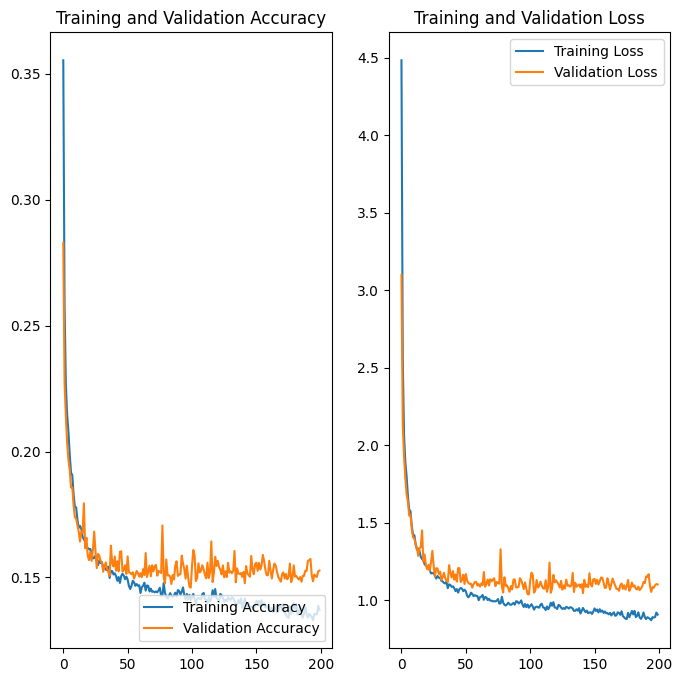

In [82]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(200)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

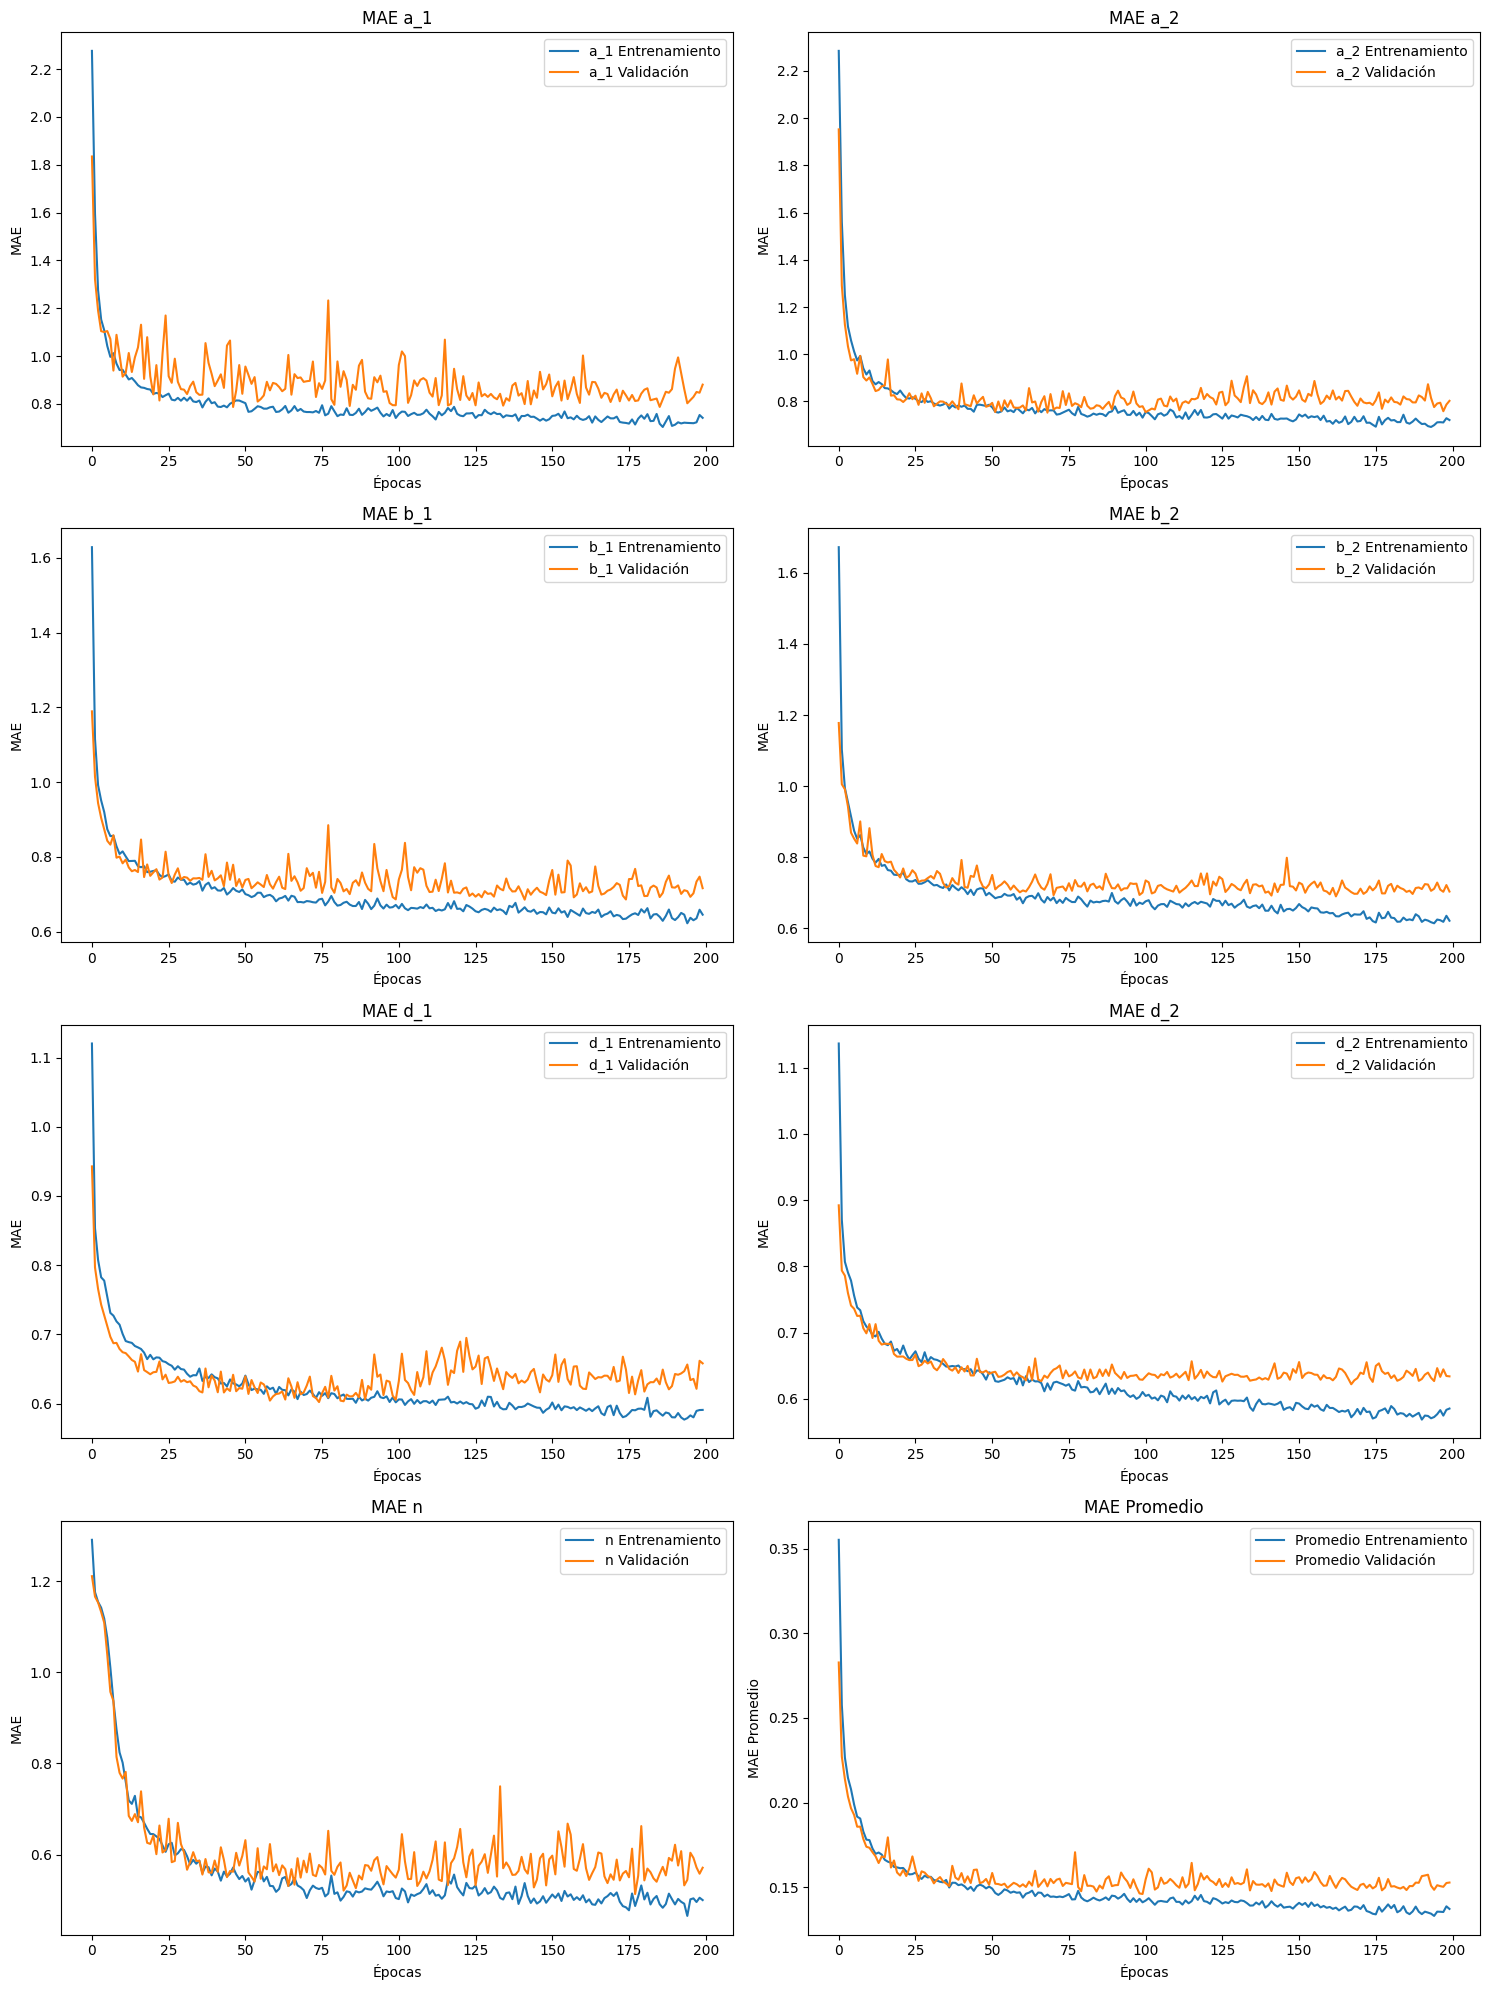

In [83]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [84]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

63/63 [==============================] - 0s 1ms/step - loss: 1.0688 - a_1: 0.7959 - a_2: 0.8177 - b_1: 0.6918 - b_2: 0.7169 - d_1: 0.6347 - d_2: 0.6446 - n: 0.5256 - mean_metric: 0.1506


In [85]:
predictions = model.predict(campvectest)

63/63 [==============================] - 0s 918us/step


In [86]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[2 3 3 0 7 2 4]
[3.116187  4.323912  3.8016603 0.571382  9.050056  3.0879393 3.616296 ]
[21 34 35 ... 36 44 35]


1.0478344559669495

In [87]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.6892777760470551, Desviación estándar del error: 0.9403157032582478, Error absoluto máximo: 5.787581443786621


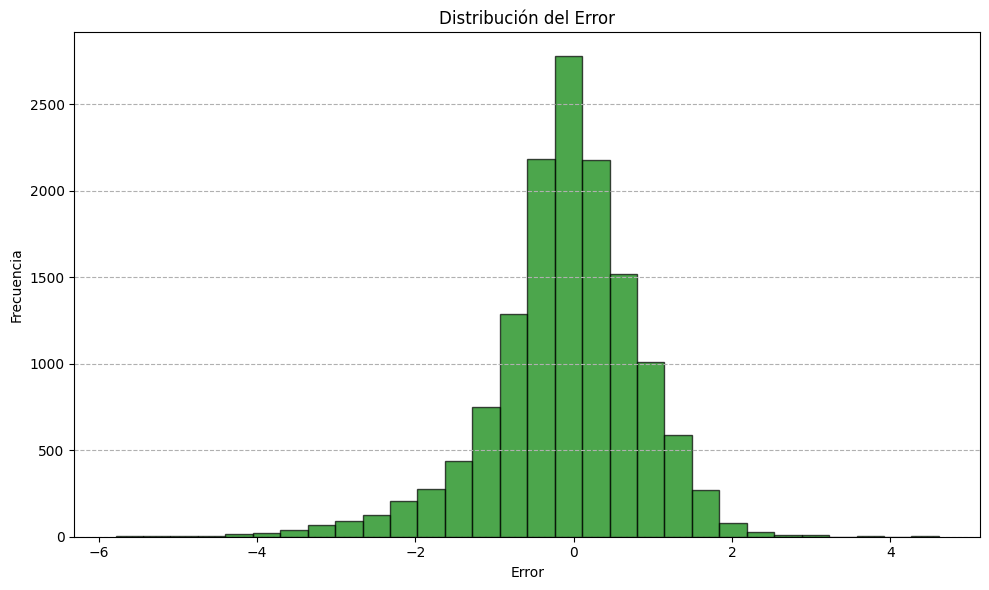

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [89]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.15930700855252938
Desviación estándar del error relativo: 0.18421409212315587
Error absoluto máximo relativo: 1.4194877232824052


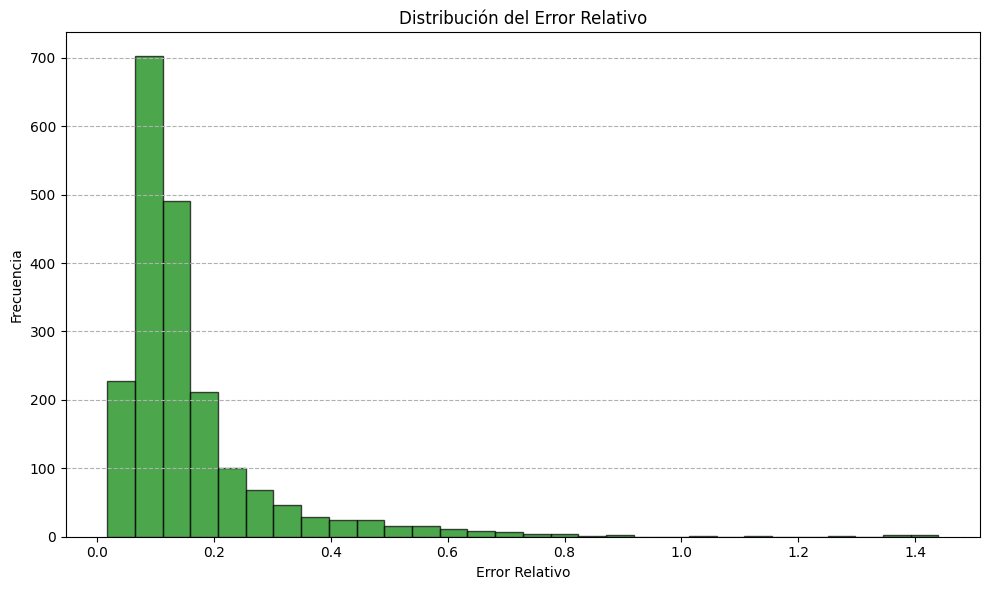

In [90]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

# Guardamos los datos Accuracy y Loss

In [91]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales con ruido/historycampvec20.csv', index=False)

# Guardamos el modelo

In [92]:
path_to_save = '../../../trained_models_noisy/grid20_traj50'

In [93]:
model.save(path_to_save + '/campovectorial20.h5')

# Importamos el modelo

In [94]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [95]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [96]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation, 'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_noisy/grid20_traj50/campovectorial20.h5', custom_objects=custom_objects)

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [130]:
import random 
import matplotlib.pyplot as plt
for i in range(0, 1):
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef = [a1, a2, b1, b2, d1, d2, n]

    for i_ci in range(0, 1):
        x_range_neg = 0
        x_range_pos = 10
        y_range_neg = 0
        y_range_pos =10

        y1 = np.linspace(x_range_neg, x_range_pos, 20)
        y2 = np.linspace(y_range_neg, y_range_pos, 20)

        Y1, Y2 = np.meshgrid(y1, y2)

        t1 = 0

        NI, NJ = Y1.shape
        u, v = np.zeros((NI, NJ)), np.zeros((NI, NJ))

        for i in range(NI):
            for j in range(NJ):
                # asignar a cada ODE a un elemento de vector
                X = Y1[i, j]
                Y = Y2[i, j]
                noise1 = np.random.normal(0, .5)
                noise2 = np.random.normal(0, .5)

                # definimos cada ODE
                dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
                dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2

                u[i, j], v[i, j] = dX_dt, dY_dt

        M = (np.hypot(u, v))
        u1, v1 = u, v
        u /= M
        v /= M

    campvecci = np.append([u], [v], axis=0)

    campvec = campvecci
    print(coef)

    
campvec = np.array(campvec)
coef = np.array(coef)

[6, 1, 4, 0, 3, 8, 3]


In [131]:
campvecnone = campvec[None, :]

## Predecimos con los datos nuevos

In [132]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 12ms/step
[[7. 2. 6. 0. 4. 9. 4.]]


## Encontramos puntos de equilibrio datos reales

In [133]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b2
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(3.333333262352669, 0.0032862708957503675)


## Graficamos con los coeficientes reales

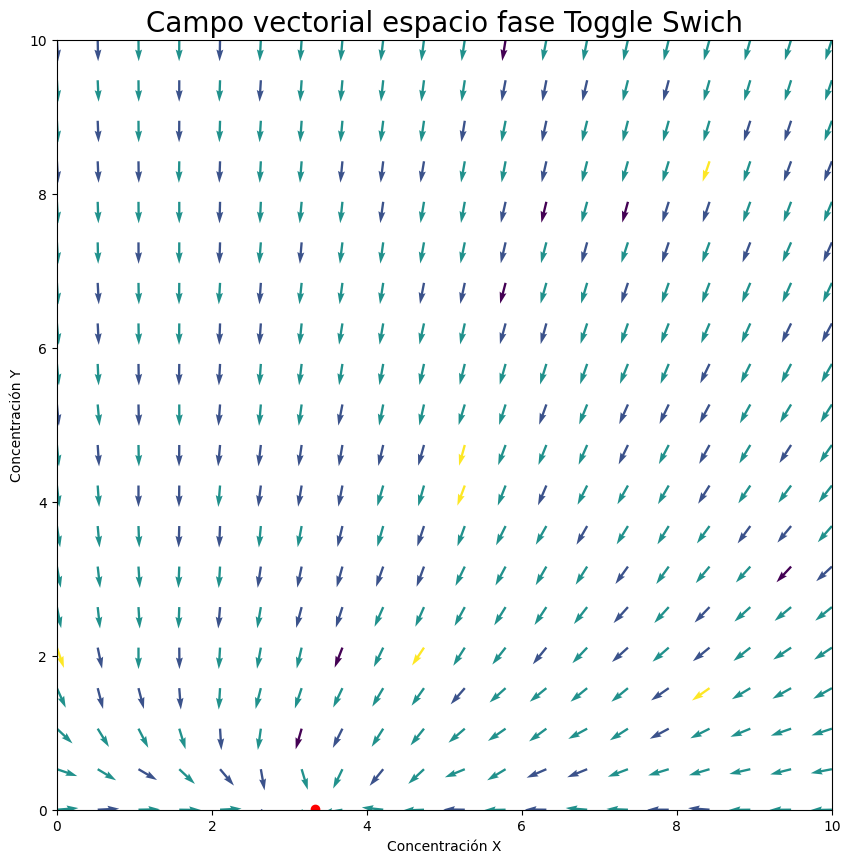

In [134]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]

y1 = np.linspace(0, 10, 20)
y2 = np.linspace(0, 10, 20)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')
plt.show()

## Encontramos puntos de equilibrio datos predecidos

In [135]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b2pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(3.2499999999734204, 0.0019741433490902504)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

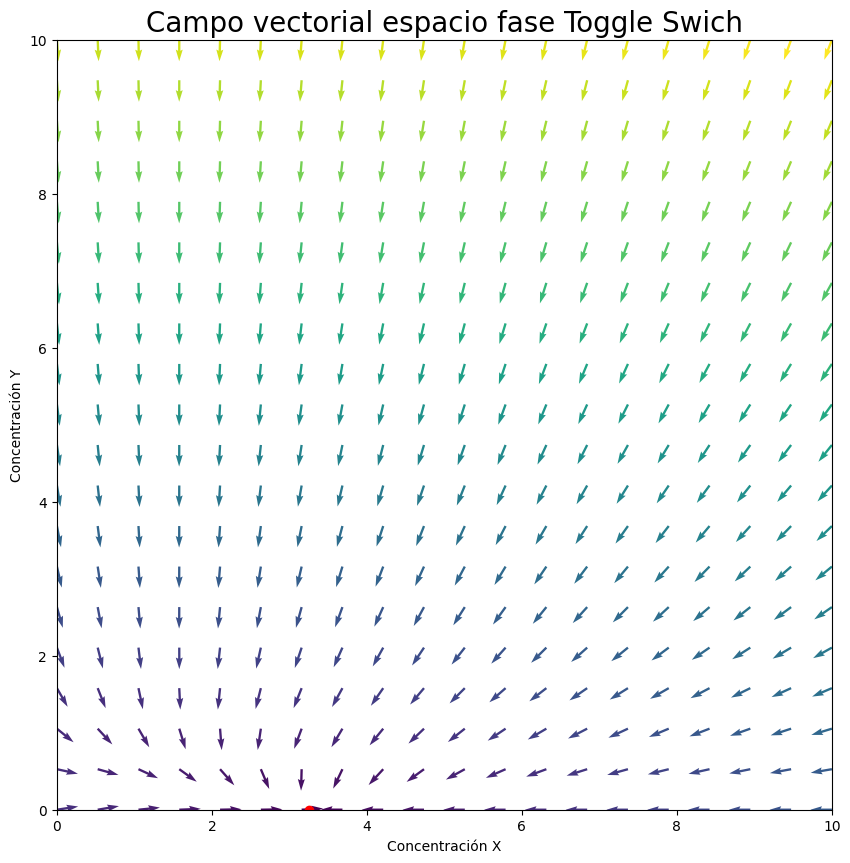

In [136]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 20)
y2pred = np.linspace(y_range_neg, y_range_pos, 20)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

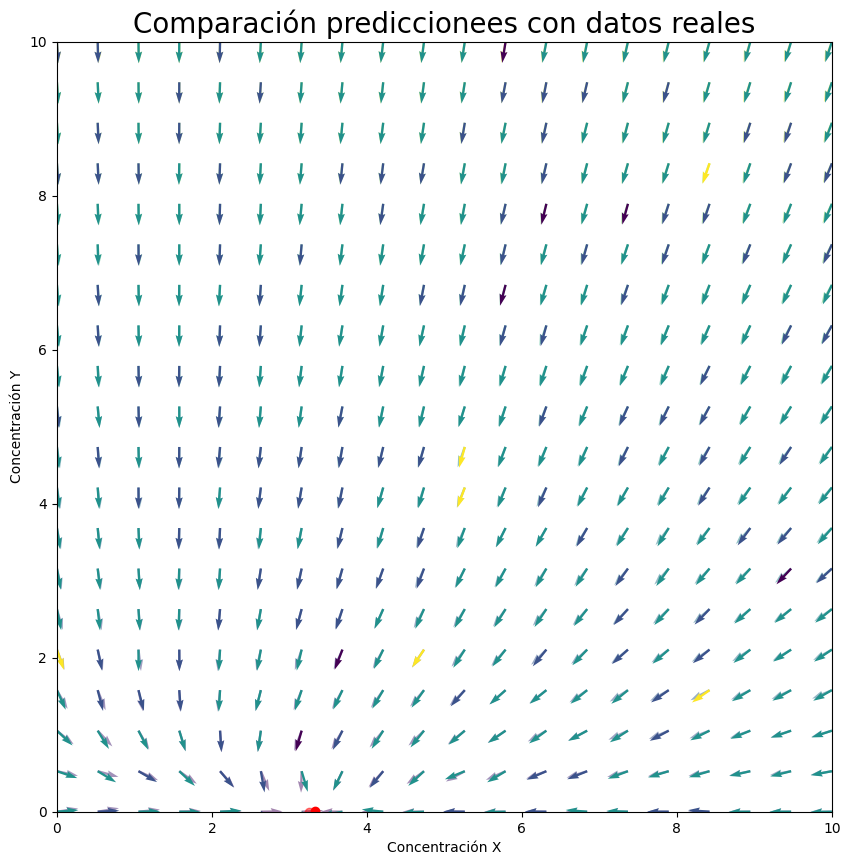

In [137]:
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5)

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1)

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5)
ax.scatter(x_values, y_values, color='red', alpha = 1)
ax.set_title('Comparación prediccionees con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

plt.show()

## Graficamos las diferencias

35.327482531537356


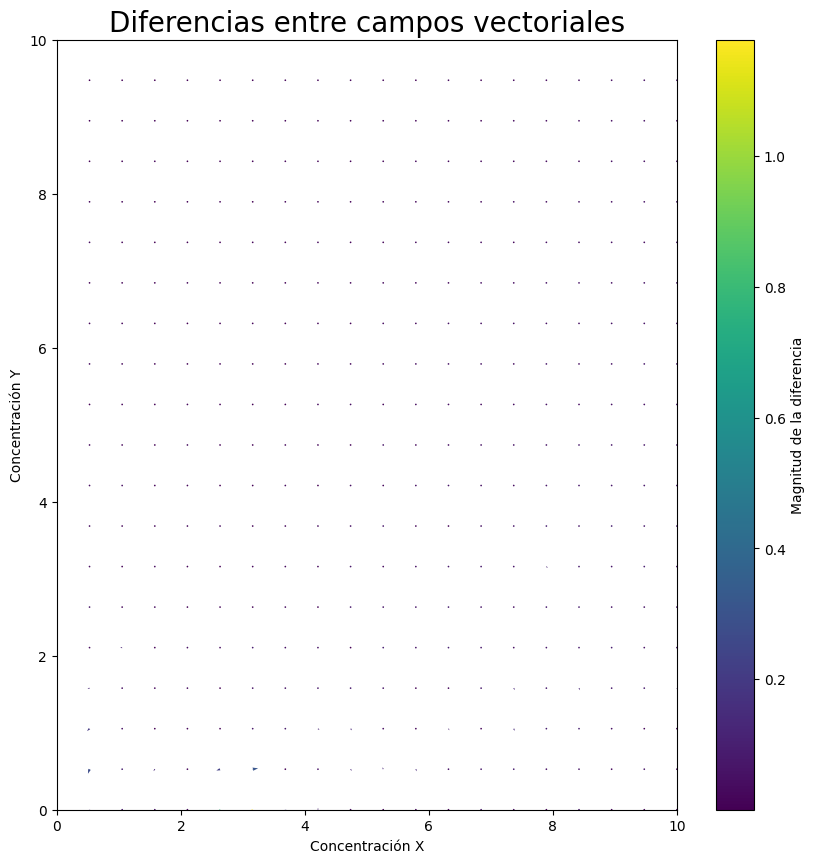

In [138]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores relativos

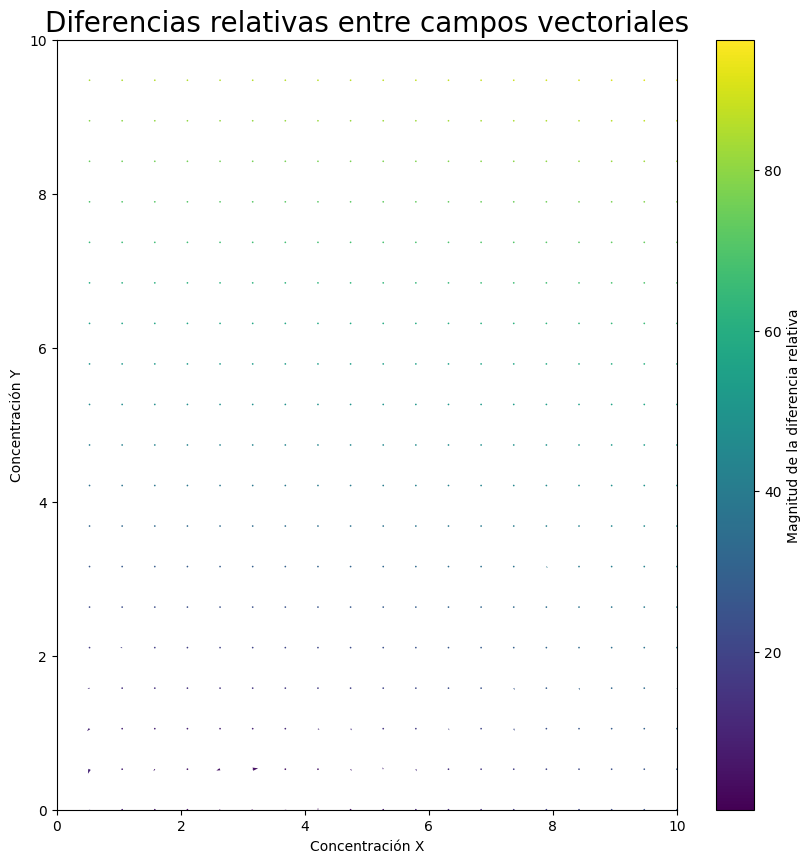

In [139]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [140]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 36.25%


## Simulamos n veces

In [141]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def ftrue(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 20)
    y2 = np.linspace(y_range_neg, y_range_pos, 20)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape
    
    
    for i in range(NI):
        for j in range(NJ):
            # asignar a cada ODE a un elemento de vector
            X = Y1[i, j]
            Y = Y2[i, j]
            noise1 = np.random.normal(0, .5)
            noise2 = np.random.normal(0, .5)
            # definimos cada ODE
            dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
            dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2
            u[i, j], v[i, j] = dX_dt, dY_dt

    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u], [v], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 20)
    y2pred = np.linspace(y_range_neg, y_range_pos, 20)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred
    
    utrue, vtrue = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    utrue, vtrue = ftrue(t1, [Y1, Y2])
    Mtrue = (np.hypot(utrue, vtrue))
    utrue /= Mtrue
    vtrue /= Mtrue  

 # Calculamos las diferencias
    u_diff = utrue - upred
    v_diff = vtrue - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 51.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 2.75%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 20.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 43.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 93.00%
--------------------------------------------
1/1 [==========================

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 45 es 12.25%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 46 es 1.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 47 es 64.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 48 es 0.25%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 49 es 45.50%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de pun

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 81.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 4.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 64.75%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 44.75%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de pun

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 133 es 13.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 67.50%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 46.25%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 5.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje d

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 4.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 10.50%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 87.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 10.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 3.25%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje d

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 221 es 40.75%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 4.75%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 25.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 21.50%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 53.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje 

... (217 outputs left out)

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9813 es 59.75%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9814 es 11.25%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9815 es 84.50%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9816 es 81.25%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9817 es 60.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porce

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9857 es 75.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9858 es 47.50%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9859 es 17.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9860 es 5.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9861 es 48.75%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcen

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9901 es 0.25%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9902 es 53.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9903 es 8.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9904 es 4.50%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9905 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaj

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9945 es 14.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9946 es 93.75%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9947 es 27.50%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9948 es 84.50%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9949 es 2.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcen

El promedio de los porcentajes es 29.87%


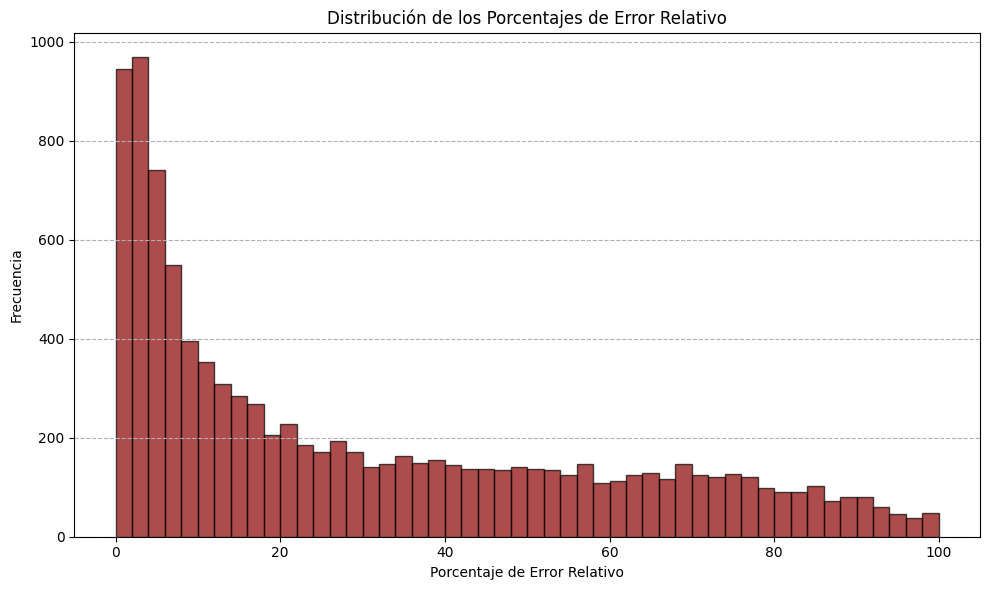

In [142]:
import matplotlib.pyplot as plt

# ...

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()
